In [13]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [14]:
image = cv2.imread(
    "D:\\practice\\medical_image_process\\image\\image1.png",
    cv2.IMREAD_GRAYSCALE
)
r1 = 70
s1 = 20

r2 = 180
s2 = 230

In [15]:
def transform_intensity(r,r1,r2,s1,s2):
    if 0 <= r and r <= r1:
        return (s1/r1)*r
    elif r1 < r and r <= r2:
        return ((s2-s1)/(r2-r1))*(r-r1)+s1
    else:
        return ((255-s2)/(255-r2))*(r-r2)+s2
    

In [16]:
def contrast_stretching(image,r1,r2,s1,s2):
    height,width = image.shape
    output = np.zeros_like(image)
    for i in range(height):
        for j in range(width):
            output[i,j] = transform_intensity(image[i,j],r1,r2,s1,s2)
    return output

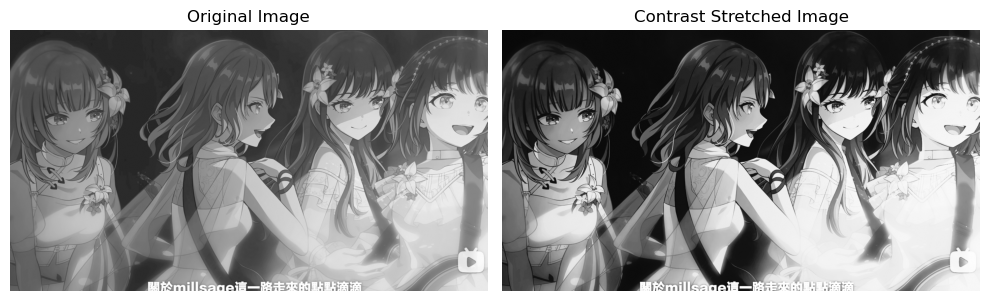

In [17]:
output = contrast_stretching(image,r1,r2,s1,s2)
cv2.imwrite(
    "outputs/q1_contrast_stretched.jpg",
    output
)
# 6. Display original and processed images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output, cmap="gray")
plt.title("Contrast Stretched Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
r_values = np.arange(256)
s_values = []

for r in r_values:
    s = transform_intensity(
        r,
        r1,
        s1,
        r2,
        s2
    )

    s_values.append(s)

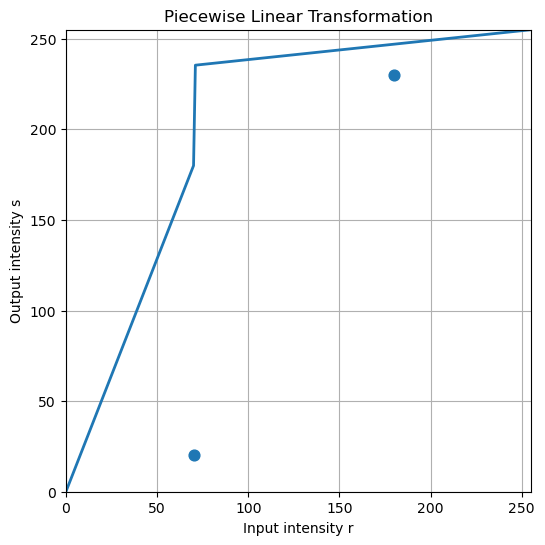

In [19]:
plt.figure(figsize=(6, 6))

plt.plot(
    r_values,
    s_values,
    linewidth=2
)

# Mark the two control points
plt.scatter(
    [r1, r2],
    [s1, s2],
    s=60
)

plt.xlabel("Input intensity r")
plt.ylabel("Output intensity s")

plt.title("Piecewise Linear Transformation")

plt.xlim(0, 255)
plt.ylim(0, 255)

plt.grid()

plt.show()

In [20]:
hist_original = np.bincount(
    image.ravel(),
    minlength=256
)

hist_output = np.bincount(
    output.ravel(),
    minlength=256
)

gray_levels = np.arange(256)


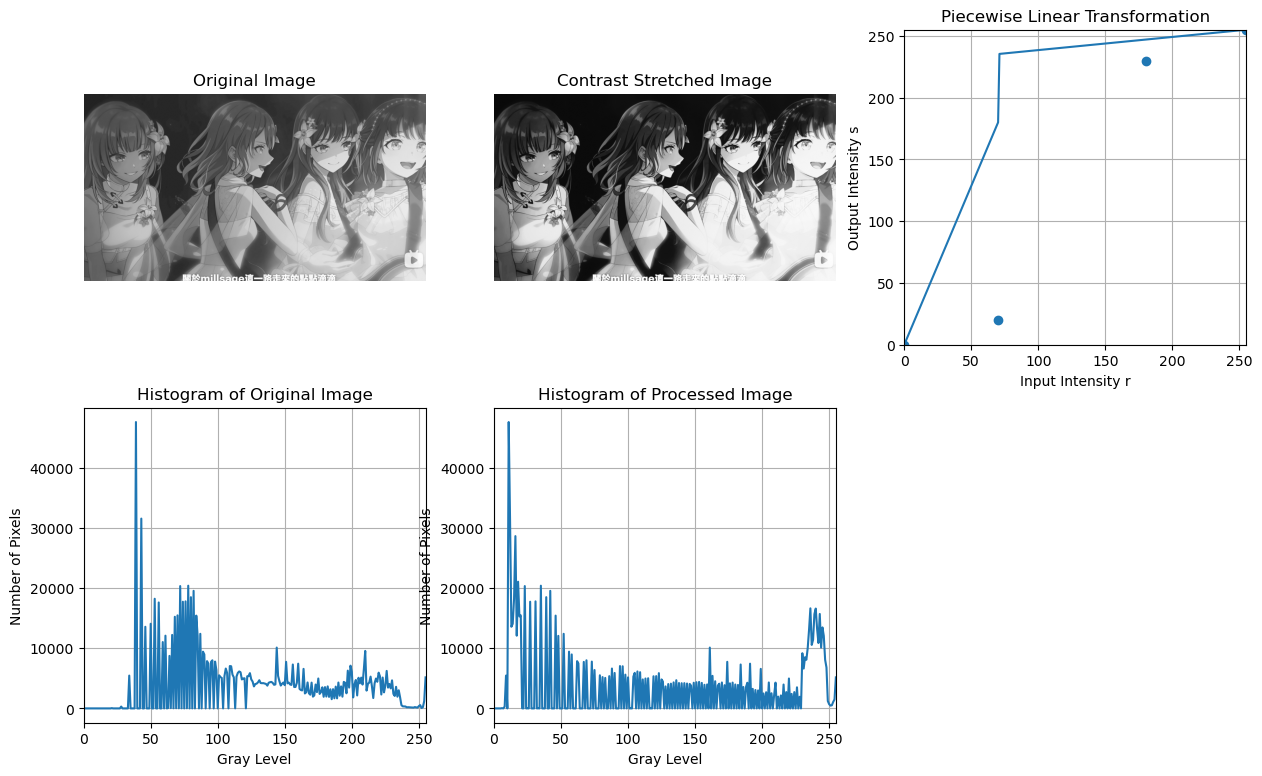

In [23]:
plt.figure(figsize=(15, 9))


# ------------------------------------------------------------
# Original image
# ------------------------------------------------------------

plt.subplot(2, 3, 1)

plt.imshow(
    image,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("Original Image")
plt.axis("off")


# ------------------------------------------------------------
# Processed image
# ------------------------------------------------------------

plt.subplot(2, 3, 2)

plt.imshow(
    output,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("Contrast Stretched Image")
plt.axis("off")


# ------------------------------------------------------------
# Piecewise linear transformation curve
# ------------------------------------------------------------

plt.subplot(2, 3, 3)

plt.plot(
    r_values,
    s_values
)

# Mark control points
plt.scatter(
    [0, r1, r2, 255],
    [0, s1, s2, 255]
)

plt.xlabel("Input Intensity r")
plt.ylabel("Output Intensity s")

plt.title("Piecewise Linear Transformation")

plt.xlim(0, 255)
plt.ylim(0, 255)

plt.grid()


# ------------------------------------------------------------
# Histogram of original image
# ------------------------------------------------------------

plt.subplot(2, 3, 4)

plt.plot(
    gray_levels,
    hist_original
)

plt.xlabel("Gray Level")
plt.ylabel("Number of Pixels")

plt.title("Histogram of Original Image")

plt.xlim(0, 255)
plt.grid()


# ------------------------------------------------------------
# Histogram of processed image
# ------------------------------------------------------------

plt.subplot(2, 3, 5)

plt.plot(
    gray_levels,
    hist_output
)

plt.xlabel("Gray Level")
plt.ylabel("Number of Pixels")

plt.title("Histogram of Processed Image")

plt.xlim(0, 255)
plt.grid()




